# Comparação entre Meta-heurísticas: ILS-VND vs. Referência

**Objetivo:** Comparar o *ILS-VND* com a meta-heurística de referência (`andre_feijo`, resultados em `project/results/andre_feijo_all`) nos datasets A, B e X ($50$ instâncias), com orçamento de cerca de 10 min por execução.

## Tabelas e Figuras Geradas

| Identificador | Conteúdo | Objetivo |
|:---:|---|---|
| **T3.1** (`tab_3_1`) | Desempenho comparativo por dataset | Visão média (média e DP do gap nas 5 sementes) e potencial máximo (melhor das 5 sementes); contagem de Gap $\le 1\%$ e Gap $= 0\%$ |
| **T3.2** (`tab_3_2`) | Confronto direto e significância | V–E–D (média e melhor réplica), diferença mediana de gap, Wilcoxon pareado e tempo |
| **F3.1** (`fig_3_1`) | Boxplot do gap médio | Mediana e variabilidade por dataset e método |
| **F3.2** (`fig_3_2`) | Escalabilidade | Nº de pedidos $\times$ ($\text{Gap}_{\text{Ref}} - \text{Gap}_{\text{ILS-VND}}$) |
| **F3.3** (`fig_3_3`) | Perfil de desempenho de Dolan & Moré | Fração de instâncias resolvidas dentro de um fator $\tau$ do melhor |

## Convenções do Estudo

- **Unidade estatística:** instância. Ambos os métodos usam as **5 primeiras réplicas** (`run_id` $1$ a $5$, `N_REPS = 5`; as sementes coincidem entre os métodos).
- **Gap (%):** $\frac{\text{MSC} - \text{obtido}}{\text{MSC}} \times 100$ por execução. *Média*: média do gap das 5 réplicas por instância. *Melhor*: menor gap das 5 réplicas. Gap negativo indica MSC superada; `Gap = 0%` significa MSC igualada ou superada (gap $\le 10^{-9}$).
- **Diferença de gap:** $\text{Gap}_{\text{Ref}} - \text{Gap}_{\text{ILS-VND}}$; valores positivos favorecem o ILS-VND.
- **V–E–D:** vitórias / empates / derrotas do ILS-VND (gap estritamente menor, tolerância $10^{-9}$).
- **Wilcoxon:** postos sinalizados pareado, **bilateral**, zeros descartados.
- **Time-to-Best:** os CSVs de resultados **não registram** o instante em que a melhor solução foi encontrada (apenas `exec_time` total). Por isso a Tabela 3.2 reporta o tempo médio total de execução; a curva de convergência não pode ser construída, e a Figura 3.3 usa o perfil de desempenho.
- **Orçamento:** ILS-VND com limite de 590 s; Referência com limite de 650 s (conforme `config.json`).


## 1. Configuração

In [1]:
import sys
import os
from pathlib import Path

# ── Localização da raiz do repositório ───────────────────────────────────────
_candidate = Path.cwd()
ROOT = None
for _p in [_candidate] + list(_candidate.parents):
    if (_p / "notebooks" / "utils" / "__init__.py").exists():
        ROOT = _p
        break
if ROOT is None:
    raise RuntimeError("Raiz do repositório não encontrada (notebooks/utils/__init__.py ausente).")

# ── Caminhos principais ───────────────────────────────────────────────────────
RESULTS_BASE   = ROOT / "project" / "results"
DATASETS_BASE  = ROOT / "datasets"
BEST_SOL_BASE  = ROOT / "best_solutions"
BEST_OBJ_CSV   = BEST_SOL_BASE / "best_objectives.csv"
VALIDATOR_DIR  = ROOT / "project" / "validator"
UTILS_DIR      = ROOT / "notebooks" / "utils"
OUTPUT_DIR     = ROOT / "notebooks" / "experimentos" / "output" / "comparacao_metaheuristicas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Adiciona os diretórios ao sys.path
for _d in [str(ROOT / "notebooks"), str(VALIDATOR_DIR), str(ROOT)]:
    if _d not in sys.path:
        sys.path.insert(0, _d)

# ── Constantes ────────────────────────────────────────────────────────────────
TOL         = 1e-9          # tolerância para empates em comparações
SEED        = 42            # semente aleatória global
DATASETS    = ["a", "b", "x"]
N_REPS      = 5             # réplicas do ILS-VND consideradas (run_id 1..N_REPS)
DS_LABELS   = {"a": "A", "b": "B", "x": "X"}
ALGOS       = ["aisle_based", "ils_vnd"]
ALGO_LABELS = {"aisle_based": "AisleBased", "ils_vnd": "ILS-VND"}

# ── Estilo de figuras ─────────────────────────────────────────────────────────
FIG_W      = 6.3           # largura útil da página em polegadas
FIG_H1     = 3.8           # altura fig_1
FIG_H2     = 3.4           # altura fig_2
FONT_MIN   = 9             # fonte mínima em pt

# Cores padrão do matplotlib (tab:blue e tab:orange) para diferenciação por algoritmo
COLORS = {
    "aisle_based": "tab:blue",     # azul padrão (C0)
    "ils_vnd": "tab:green",           # verde padrão (C2)
}
MARKERS = {
    "aisle_based": "o",            # círculo
    "ils_vnd": "s",                   # quadrado
}

# ── Configuração global de matplotlib ────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({
    "font.size":        FONT_MIN,
    "axes.titlesize":   FONT_MIN,
    "axes.labelsize":   FONT_MIN,
    "xtick.labelsize":  FONT_MIN,
    "ytick.labelsize":  FONT_MIN,
    "legend.fontsize":  FONT_MIN,
    "figure.dpi":       150,
    "savefig.dpi":      300,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
})

print("ROOT          :", ROOT)
print("RESULTS_BASE  :", RESULTS_BASE)
print("DATASETS_BASE :", DATASETS_BASE)
print("BEST_OBJ_CSV  :", BEST_OBJ_CSV)
print("VALIDATOR_DIR :", VALIDATOR_DIR)
print("OUTPUT_DIR    :", OUTPUT_DIR)


ROOT          : /home/vinicius/Documents/CEFET/TCC/pfc2
RESULTS_BASE  : /home/vinicius/Documents/CEFET/TCC/pfc2/project/results
DATASETS_BASE : /home/vinicius/Documents/CEFET/TCC/pfc2/datasets
BEST_OBJ_CSV  : /home/vinicius/Documents/CEFET/TCC/pfc2/best_solutions/best_objectives.csv
VALIDATOR_DIR : /home/vinicius/Documents/CEFET/TCC/pfc2/project/validator
OUTPUT_DIR    : /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/comparacao_metaheuristicas


In [2]:
# ── Ajustes específicos desta seção ──────────────────────────────────────────
ALGOS       = ["ils_vnd", "ref"]
ALGO_LABELS = {"ils_vnd": "ILS-VND", "ref": "Referência"}
COLORS      = {"ils_vnd": "tab:green", "ref": "tab:red"}
MARKERS     = {"ils_vnd": "D", "ref": "o"}
FIG_H3      = 3.6


## 2. Utilitários

In [3]:
import re
import io
import csv
import tempfile
import numpy as np
import pandas as pd
from scipy import stats

# ── Formatador numérico com vírgula decimal ───────────────────────────────────
def fmt(value, decimals=2):
    """Formata número com vírgula como separador decimal."""
    if pd.isna(value):
        return "--"
    if isinstance(value, (int, np.integer)):
        return f"{int(value)}"
    fmt_str = f"{value:.{decimals}f}"
    return fmt_str.replace(".", ",")

# ── Escape LaTeX ──────────────────────────────────────────────────────────────
def tex_escape(text, raw=False):
    """Escapa texto para LaTeX. Se raw=True, retorna sem escape (modo matemático)."""
    if raw:
        return str(text)
    s = str(text)
    s = s.replace("\\", r"\textbackslash{}")
    s = s.replace("&",  r"\&")
    s = s.replace("%",  r"\%")
    s = s.replace("#",  r"\#")
    s = s.replace("_",  r"\_")
    s = s.replace("{",  r"\{")
    s = s.replace("}",  r"\}")
    s = s.replace("~",  r"\textasciitilde{}")
    s = s.replace("^",  r"\textasciicircum{}")
    return s

# ── Escritor de tabular booktabs ──────────────────────────────────────────────
def make_tabular(header_rows, data_rows, col_align, raw_cols=None):
    if raw_cols is None:
        raw_cols = set()

    lines = []
    lines.append(r"\small")
    lines.append(r"\begin{tabular}{" + col_align + "}")
    lines.append(r"\toprule")

    for h_row in header_rows:
        cells_tex = []
        for j, cell in enumerate(h_row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(txt, raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")
    lines.append(r"\midrule")

    for row in data_rows:
        cells_tex = []
        for j, cell in enumerate(row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(str(txt), raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")
    return "\n".join(lines)

# ── Gravador CSV + .tex ───────────────────────────────────────────────────────
def salvar_tabela(nome, df_csv, tex_str, output_dir=OUTPUT_DIR):
    csv_path = output_dir / f"{nome}.csv"
    tex_path = output_dir / f"{nome}.tex"
    df_csv.to_csv(csv_path, index=False)
    tex_path.write_text(tex_str, encoding="utf-8")
    return csv_path, tex_path

# ── Teste de sinais exato bilateral ──────────────────────────────────────────
def teste_sinais(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs_nonzero = diffs[np.abs(diffs) > TOL]
    n = len(diffs_nonzero)
    if n == 0:
        return np.nan
    k = int(np.sum(diffs_nonzero > 0))
    result = stats.binomtest(k, n, p=0.5, alternative="two-sided")
    return result.pvalue

# ── Resumo pareado ────────────────────────────────────────────────────────────
def resumo_pareado(vals_a, vals_b, maior_e_melhor_a=False):
    a = np.asarray(vals_a, dtype=float)
    b = np.asarray(vals_b, dtype=float)
    diffs = a - b
    if maior_e_melhor_a:
        wins   = int(np.sum(diffs >  TOL))
        losses = int(np.sum(diffs < -TOL))
    else:
        wins   = int(np.sum(diffs < -TOL))
        losses = int(np.sum(diffs >  TOL))
    ties = len(diffs) - wins - losses
    return wins, ties, losses, diffs

# ── Verificação estrutural de .tex ────────────────────────────────────────────
def verificar_tex(tex_str, nome=""):
    erros = []
    if re.search(r'\\\\(begin|end|toprule|midrule|bottomrule|small)', tex_str):
        erros.append("barras duplicadas em comandos estruturais")
    begins = re.findall(r'\\begin\{(\w+)\}', tex_str)
    ends   = re.findall(r'\\end\{(\w+)\}', tex_str)
    if sorted(begins) != sorted(ends):
        erros.append(f"begin/end desbalanceados: {begins} vs {ends}")
    tex_lines = [l for l in tex_str.split("\n") if l.strip().endswith(r"\\") and "&" in l]
    counts = [l.count("&") for l in tex_lines]
    if len(set(counts)) > 1:
        erros.append(f"número de & inconsistente por linha: {set(counts)}")
    return erros

# ─── Auto-teste ───────────────────────────────────────────────────────────────
with tempfile.TemporaryDirectory() as _tmpdir:
    _hdr = [["Dataset", "Algoritmo", "Mediana", "Média"]]
    _dat = [
        ["A", "AisleBased", fmt(1.23), fmt(2.34)],
        ["B", "OrderBased", fmt(5.67), fmt(6.78)],
    ]
    _tex = make_tabular(_hdr, _dat, "llrr")
    _erros = verificar_tex(_tex, "auto-teste")
    if _erros:
        print("AUTO-TESTE FALHOU:", _erros)
    else:
        print("Auto-teste dos utilitários: ok")
    assert "1,23" in _tex and "2,34" in _tex, "vírgula decimal ausente"
    print("Vírgula decimal: ok")


Auto-teste dos utilitários: ok
Vírgula decimal: ok


## 3. Carga dos Resultados

In [4]:
from utils.resultados import carregar_resultados
from validator import parse_instance

df_g = carregar_resultados("ils_vnd_all", RESULTS_BASE);        df_g["algo_id"] = "ils_vnd"
df_r = carregar_resultados("andre_feijo_all", RESULTS_BASE); df_r["algo_id"] = "ref"
df_raw = pd.concat([df_g, df_r], ignore_index=True)
df_raw = df_raw[df_raw["run_id"] <= N_REPS].copy()

print("Execuções por algoritmo e dataset (run_id <= %d):" % N_REPS)
display(df_raw.groupby(["algo_id", "dataset"]).size().unstack(fill_value=0))
_inf = df_raw[df_raw["status"] != "feasible"]
print("Execuções não viáveis:", len(_inf))
if len(_inf):
    display(_inf[["dataset", "instance", "algo_id", "status", "reason"]])
df_viable = df_raw[df_raw["status"] == "feasible"].copy()
seeds_ok = (df_g[df_g.run_id <= N_REPS].groupby(["dataset", "instance", "run_id"])["seed"].first()
            .equals(df_r[df_r.run_id <= N_REPS].groupby(["dataset", "instance", "run_id"])["seed"].first()))
print("Sementes idênticas entre ILS-VND e Referência:", seeds_ok)


Execuções por algoritmo e dataset (run_id <= 5):


dataset,a,b,x
algo_id,,,
gvns,100,75,75
ref,100,75,75


Execuções não viáveis: 0
Sementes idênticas entre GVNS e Referência: True


## 4. MSC, Gap e Agregação por Instância

In [5]:
_m = pd.read_csv(BEST_OBJ_CSV)
_m["instance_key"] = _m["instance"].str.strip().str.replace("\r", "", regex=False).str.replace(".txt", "", regex=False)
_m["dataset"] = _m["dataset"].str.strip()
msc_dict = {(r["dataset"], r["instance_key"]): r["best_objective"] for _, r in _m.iterrows()}
df_viable["msc"] = [msc_dict.get(k, np.nan) for k in zip(df_viable["dataset"], df_viable["instance"])]
df_viable["gap"] = (df_viable["msc"] - df_viable["objective"]) / df_viable["msc"] * 100.0

df_inst = df_viable.groupby(["dataset", "instance", "algo_id"]).agg(
    gap_media=("gap", "mean"), gap_melhor=("gap", "min"),
    gap_dp=("gap", lambda s: s.std(ddof=1) if len(s) > 1 else 0.0),
    obj_media=("objective", "mean"), obj_melhor=("objective", "max"),
    tempo=("exec_time", "mean"), n_runs=("gap", "size"),
).reset_index()

_n_orders = {}
for ds in DATASETS:
    for f in sorted((DATASETS_BASE / ds).glob("*.txt")):
        _n_orders[(ds, f.stem)] = parse_instance(f)["n_orders"]

_g = df_inst[df_inst.algo_id == "ils_vnd"].set_index(["dataset", "instance"])
_r = df_inst[df_inst.algo_id == "ref"].set_index(["dataset", "instance"])
_idx = _g.index.intersection(_r.index)
df_par = pd.DataFrame({
    "g_med": _g.loc[_idx, "gap_media"], "r_med": _r.loc[_idx, "gap_media"],
    "g_best": _g.loc[_idx, "gap_melhor"], "r_best": _r.loc[_idx, "gap_melhor"],
    "g_dp": _g.loc[_idx, "gap_dp"], "r_dp": _r.loc[_idx, "gap_dp"],
    "g_obj_med": _g.loc[_idx, "obj_media"], "r_obj_med": _r.loc[_idx, "obj_media"],
    "g_obj_best": _g.loc[_idx, "obj_melhor"], "r_obj_best": _r.loc[_idx, "obj_melhor"],
    "g_tempo": _g.loc[_idx, "tempo"], "r_tempo": _r.loc[_idx, "tempo"],
}).reset_index()
df_par["n_orders"] = [_n_orders[k] for k in zip(df_par["dataset"], df_par["instance"])]
df_par["dif_med"] = df_par["r_med"] - df_par["g_med"]
df_par["dif_best"] = df_par["r_best"] - df_par["g_best"]
print("Instâncias pareadas:", len(df_par), "| n_pedidos min/máx:", df_par.n_orders.min(), df_par.n_orders.max())
print("Execuções por instância:", sorted(df_inst.n_runs.unique()))
display(df_par.head())


Instâncias pareadas: 50 | n_pedidos min/máx: 5 68064
Execuções por instância: [np.int64(5)]


,dataset,instance,g_med,r_med,g_best,r_best,g_dp,r_dp,g_obj_med,r_obj_med,g_obj_best,r_obj_best,g_tempo,r_tempo,n_orders,dif_med,dif_best
0,a,instance_0001,0.0,0.0,0.0,0.0,0.0,0.0,15.000,15.000,15.000,15.000,12.2564,0.0946,61,0.0,0.0
1,a,instance_0002,0.0,0.0,0.0,0.0,0.0,0.0,2.000,2.000,2.000,2.000,3.6108,0.0696,7,0.0,0.0
2,a,instance_0003,0.0,0.0,0.0,0.0,0.0,0.0,12.000,12.000,12.000,12.000,22.7258,0.1322,82,0.0,0.0
3,a,instance_0004,0.0,0.0,0.0,0.0,0.0,0.0,3.500,3.500,3.500,3.500,5.8214,0.0974,16,0.0,0.0
4,a,instance_0005,0.0,0.0,0.0,0.0,0.0,0.0,177.875,177.875,177.875,177.875,590.3996,315.5894,2625,0.0,0.0


## 5. Tabela 3.1: Desempenho Comparativo das Meta-heurísticas

### Legenda e Descrição das Colunas
* **Dataset:** `A` (20), `B` (15), `X` (15) ou `Geral` (50 instâncias).
* **Método:** `ILS-VND` ou `Referência`.
* **Média (DP):** média e desvio padrão amostral, entre instâncias, do gap médio das 5 sementes (%).
* **DP sem.:** média, entre instâncias, do desvio padrão do gap entre as 5 sementes (p.p.).
* **Melhor:** média, entre instâncias, do gap da melhor das 5 sementes (%).
* **Gap $\le 1\%$:** nº de instâncias com gap $\le 1\%$, na visão média | visão melhor.
* **Gap $= 0\%$:** nº de instâncias com MSC igualada ou superada, na visão média | visão melhor.


In [6]:
def stats_31(df, p):
    m, b, dp = df[f"{p}_med"], df[f"{p}_best"], df[f"{p}_dp"]
    return dict(media=m.mean(), dp=m.std(ddof=1), dp_sem=dp.mean(), melhor=b.mean(),
                le1_m=int((m <= 1 + TOL).sum()), le1_b=int((b <= 1 + TOL).sum()),
                z_m=int((m <= TOL).sum()), z_b=int((b <= TOL).sum()), N=len(df))

HEADER_31 = [["Dataset", "Método", "Média (DP)", "DP sem.", "Melhor",
              (r"Gap $\leq$ 1\% (méd.\,|\,melhor)", True), (r"Gap $=$ 0\% (méd.\,|\,melhor)", True)]]
csv31, tex31 = [], []
for ds in DATASETS + [None]:
    sub = df_par[df_par.dataset == ds] if ds else df_par
    lbl = f"{DS_LABELS[ds]} ({len(sub)})" if ds else f"Geral ({len(sub)})"
    for i, (p, nome) in enumerate([("g", "ILS-VND"), ("r", "Referência")]):
        s = stats_31(sub, p)
        csv31.append([lbl, nome, s["media"], s["dp"], s["dp_sem"], s["melhor"],
                      f"{s['le1_m']}|{s['le1_b']}", f"{s['z_m']}|{s['z_b']}"])
        tex31.append([lbl if i == 0 else "", nome, f"{fmt(s['media'])} ({fmt(s['dp'])})", fmt(s["dp_sem"], 3),
                      fmt(s["melhor"]), (f"{s['le1_m']} | {s['le1_b']}", False), (f"{s['z_m']} | {s['z_b']}", False)])
df_tab31 = pd.DataFrame(csv31, columns=["Dataset", "Metodo", "Media", "DP_inst", "DP_sementes", "Melhor", "Gap_le1_media|melhor", "Gap_0_media|melhor"])
tex_31 = make_tabular(HEADER_31, tex31, "llrrrcc", raw_cols={5, 6})
LEG_31 = """% Legenda:
% - Dataset (N): A, B, X ou Geral.
% - Média (DP): média e desvio padrão entre instâncias do gap médio das 5 sementes (%).
% - DP sem.: média entre instâncias do desvio padrão do gap entre as 5 sementes (p.p.).
% - Melhor: média entre instâncias do gap da melhor semente (%).
% - Gap <= 1% e Gap = 0% (MSC igualada/superada): nº de instâncias, visão média | visão melhor."""
salvar_tabela("tab_3_1", df_tab31, tex_31 + "\n\n" + LEG_31)
display(df_tab31); print(tex_31)


,Dataset,Metodo,Media,DP_inst,DP_sementes,Melhor,Gap_le1_media|melhor,Gap_0_media|melhor
0,A (20),GVNS,0.149949,0.526953,2.954544e-02,0.122833,19|19,18|18
1,A (20),Referência,0.018905,0.058255,0.000000e+00,0.018905,20|20,18|18
2,B (15),GVNS,0.036233,0.095041,3.031675e-02,0.009306,15|15,10|11
3,B (15),Referência,0.021291,0.064990,0.000000e+00,0.021291,15|15,12|12
4,X (15),GVNS,0.365424,0.819512,8.107835e-02,0.285378,13|13,9|10
5,X (15),Referência,0.019617,0.057518,2.068778e-18,0.019617,15|15,13|13
6,Geral (50),GVNS,0.180477,0.565119,4.523670e-02,0.137538,47|47,37|39
7,Geral (50),Referência,0.019834,0.058898,6.206335e-19,0.019834,50|50,43|43


\small
\begin{tabular}{llrrrcc}
\toprule
Dataset & Método & Média (DP) & DP sem. & Melhor & Gap $\leq$ 1\% (méd.\,|\,melhor) & Gap $=$ 0\% (méd.\,|\,melhor) \\
\midrule
A (20) & GVNS & 0,15 (0,53) & 0,030 & 0,12 & 19 | 19 & 18 | 18 \\
 & Referência & 0,02 (0,06) & 0,000 & 0,02 & 20 | 20 & 18 | 18 \\
B (15) & GVNS & 0,04 (0,10) & 0,030 & 0,01 & 15 | 15 & 10 | 11 \\
 & Referência & 0,02 (0,06) & 0,000 & 0,02 & 15 | 15 & 12 | 12 \\
X (15) & GVNS & 0,37 (0,82) & 0,081 & 0,29 & 13 | 13 & 9 | 10 \\
 & Referência & 0,02 (0,06) & 0,000 & 0,02 & 15 | 15 & 13 | 13 \\
Geral (50) & GVNS & 0,18 (0,57) & 0,045 & 0,14 & 47 | 47 & 37 | 39 \\
 & Referência & 0,02 (0,06) & 0,000 & 0,02 & 50 | 50 & 43 | 43 \\
\bottomrule
\end{tabular}


## 6. Tabela 3.2: Confronto Direto e Significância Estatística

### Legenda e Descrição das Colunas
* **Dataset / Visão:** `Média` (gap médio das 5 sementes) ou `Melhor` (melhor semente).
* **V–E–D:** vitórias / empates / derrotas do ILS-VND contra a Referência (gap estritamente menor).
* **Δ mediana (p.p.):** mediana de $\text{Gap}_{\text{Ref}} - \text{Gap}_{\text{ILS-VND}}$ (positivo favorece o ILS-VND).
* **$p$ (Wilcoxon):** postos sinalizados pareado, bilateral.
* **Tempo ILS-VND / Ref. (s):** tempo médio de execução total por instância (a coluna Time-to-Best não existe nos logs; ver convenções).


In [7]:
def wilcoxon_p(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[np.abs(d) > TOL]
    return np.nan if len(d) == 0 else stats.wilcoxon(d, alternative="two-sided", zero_method="wilcox").pvalue

def fmt_p(p):
    if pd.isna(p): return "--"
    return r"$<$ 0,001" if p < 0.001 else fmt(p, 3)

HEADER_32 = [["Dataset", "Visão", (r"V--E--D", True), r"$\Delta$ mediana (p.p.)", (r"$p$ (Wilcoxon)", True),
              "Tempo ILS-VND (s)", "Tempo Ref. (s)"]]
csv32, tex32 = [], []
for ds in DATASETS + [None]:
    sub = df_par[df_par.dataset == ds] if ds else df_par
    lbl = DS_LABELS[ds] if ds else "Geral"
    for i, (visao, g, r, dif) in enumerate([("Média", "g_med", "r_med", "dif_med"), ("Melhor", "g_best", "r_best", "dif_best")]):
        w, t, l, _ = resumo_pareado(sub[g].values, sub[r].values)
        p = wilcoxon_p(sub[r].values, sub[g].values)
        tg, tr = sub["g_tempo"].mean(), sub["r_tempo"].mean()
        csv32.append([lbl, visao, f"{w}-{t}-{l}", sub[dif].median(), p, tg, tr])
        tex32.append([lbl if i == 0 else "", visao, (f"{w}--{t}--{l}", False), fmt(sub[dif].median(), 3),
                      (fmt_p(p), True), fmt(tg, 1) if i == 0 else "", fmt(tr, 1) if i == 0 else ""])
df_tab32 = pd.DataFrame(csv32, columns=["Dataset", "Visao", "V_E_D", "Delta_mediana_pp", "p_wilcoxon", "Tempo_ILS_VND_s", "Tempo_Ref_s"])
tex_32 = make_tabular(HEADER_32, tex32, "llcrrrr", raw_cols={2, 4})
LEG_32 = """% Legenda:
% - Visão: Média (gap médio das 5 sementes) ou Melhor (melhor semente).
% - V--E--D: vitórias / empates / derrotas do ILS-VND (gap estritamente menor).
% - Delta mediana: mediana de Gap_Ref - Gap_ILS_VND (p.p.); positivo favorece o ILS-VND.
% - p (Wilcoxon): postos sinalizados pareado, bilateral.
% - Tempo: tempo médio total de execução por instância (Time-to-Best nao registrado nos logs)."""
salvar_tabela("tab_3_2", df_tab32, tex_32 + "\n\n" + LEG_32)
display(df_tab32); print(tex_32)


,Dataset,Visao,V_E_D,Delta_mediana_pp,p_wilcoxon,Tempo_GVNS_s,Tempo_Ref_s
0,A,Média,0-18-2,0.0,0.500000,316.817100,70.320230
1,A,Melhor,0-18-2,0.0,0.500000,316.817100,70.320230
2,B,Média,2-8-5,0.0,0.296875,567.818413,222.231853
3,B,Melhor,3-9-3,0.0,0.562500,567.818413,222.231853
4,X,Média,2-7-6,0.0,0.195312,593.004000,319.699253
5,X,Melhor,2-8-5,0.0,0.218750,593.004000,319.699253
6,Geral,Média,4-33-13,0.0,0.023224,474.973564,190.707424
7,Geral,Melhor,5-35-10,0.0,0.187622,474.973564,190.707424


\small
\begin{tabular}{llcrrrr}
\toprule
Dataset & Visão & V--E--D & $\textbackslash\{\}Delta$ mediana (p.p.) & $p$ (Wilcoxon) & Tempo GVNS (s) & Tempo Ref. (s) \\
\midrule
A & Média & 0--18--2 & 0,000 & 0,500 & 316,8 & 70,3 \\
 & Melhor & 0--18--2 & 0,000 & 0,500 &  &  \\
B & Média & 2--8--5 & 0,000 & 0,297 & 567,8 & 222,2 \\
 & Melhor & 3--9--3 & 0,000 & 0,562 &  &  \\
X & Média & 2--7--6 & 0,000 & 0,195 & 593,0 & 319,7 \\
 & Melhor & 2--8--5 & 0,000 & 0,219 &  &  \\
Geral & Média & 4--33--13 & 0,000 & 0,023 & 475,0 & 190,7 \\
 & Melhor & 5--35--10 & 0,000 & 0,188 &  &  \\
\bottomrule
\end{tabular}


## 7. Figura 3.1: Boxplot do Gap Médio por Dataset

Eixo $y$ em escala symlog (linear até 1%). Cada ponto é uma instância (gap médio das 5 sementes).

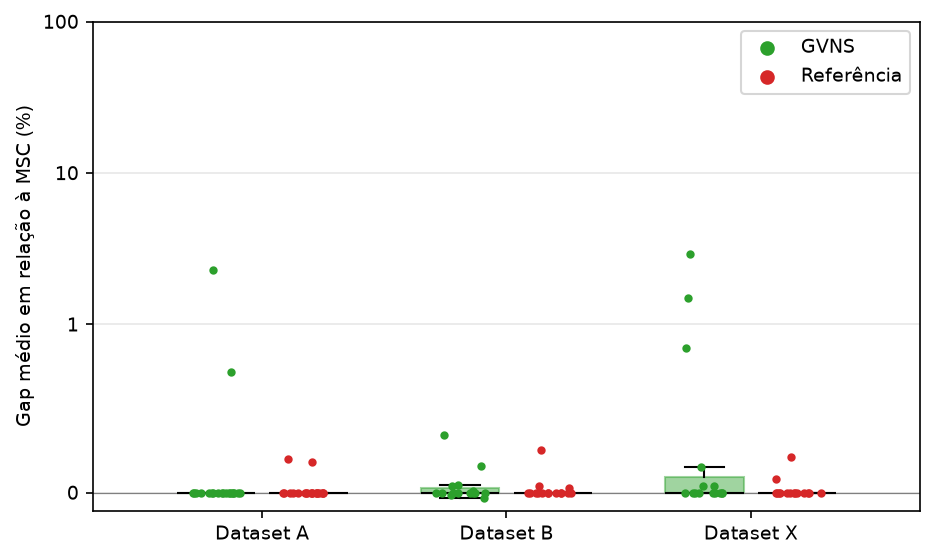

In [8]:
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H1))
rng = np.random.default_rng(SEED)
w = 0.32
for k, (p, a) in enumerate([("g_med", "ils_vnd"), ("r_med", "ref")]):
    pos = np.arange(len(DATASETS)) + (k - 0.5) * (w + 0.06)
    data = [df_par[df_par.dataset == ds][p].values for ds in DATASETS]
    bp = ax.boxplot(data, positions=pos, widths=w, patch_artist=True, showfliers=False,
                    medianprops=dict(color="black"))
    for box in bp["boxes"]:
        box.set(facecolor=COLORS[a], alpha=0.45, edgecolor=COLORS[a])
    for x0, d in zip(pos, data):
        ax.scatter(x0 + rng.uniform(-w / 3, w / 3, len(d)), d, s=9, color=COLORS[a], zorder=3)
    ax.scatter([], [], color=COLORS[a], label=ALGO_LABELS[a])
ax.set_yscale("symlog", linthresh=1.0)
ax.set_yticks([0, 1, 10, 100]); ax.set_yticklabels(["0", "1", "10", "100"])
ax.set_xticks(range(len(DATASETS))); ax.set_xticklabels([f"Dataset {DS_LABELS[d]}" for d in DATASETS])
ax.set_ylabel("Gap médio em relação à MSC (%)")
ax.axhline(0, color="0.5", lw=0.6)
ax.grid(axis="y", alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_1.pdf", bbox_inches="tight"); fig.savefig(OUTPUT_DIR / "fig_3_1.png", bbox_inches="tight")
plt.show()


## 8. Figura 3.2: Escalabilidade — Nº de Pedidos $\times$ ($\text{Gap}_{\text{Ref}} - \text{Gap}_{\text{ILS-VND}}$)

Pontos acima de zero indicam vitória do ILS-VND (gap médio das 5 sementes). Eixo $x$ em escala logarítmica; eixo $y$ symlog.

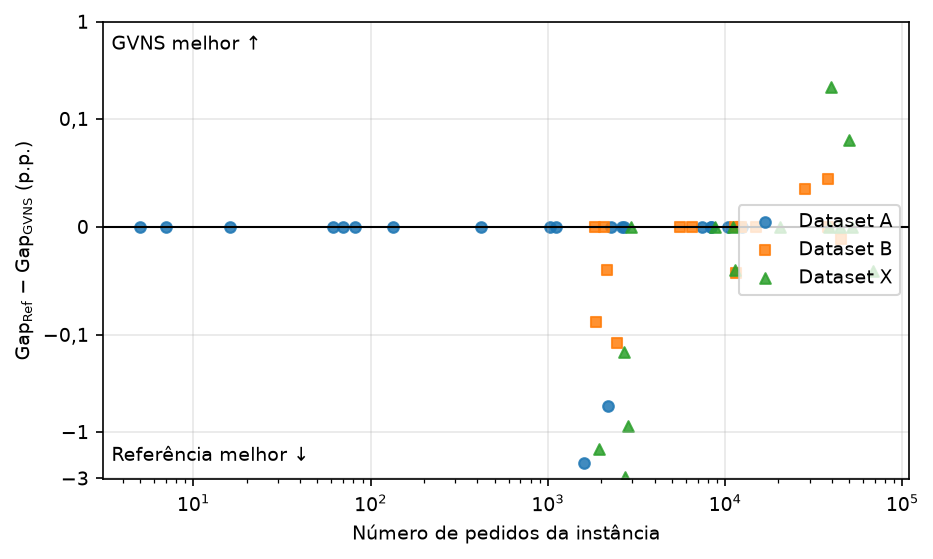

Correlação de Spearman (log n_pedidos vs diferença): SignificanceResult(statistic=np.float64(0.21370619285193312), pvalue=np.float64(0.136175350176402))


In [9]:
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H1))
for ds in DATASETS:
    s = df_par[df_par.dataset == ds]
    ax.scatter(s["n_orders"], s["dif_med"], s=26, marker={"a": "o", "b": "s", "x": "^"}[ds],
               label=f"Dataset {DS_LABELS[ds]}", alpha=0.85)
ax.axhline(0, color="black", lw=1)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=0.1)
ax.set_yticks([-3, -1, -0.1, 0, 0.1, 1]); ax.set_yticklabels(["−3", "−1", "−0,1", "0", "0,1", "1"])
ax.set_xlabel("Número de pedidos da instância")
ax.set_ylabel(r"Gap$_{\mathrm{Ref}}$ − Gap$_{\mathrm{ILS-VND}}$ (p.p.)")
ax.text(0.01, 0.97, "ILS-VND melhor ↑", transform=ax.transAxes, va="top", fontsize=FONT_MIN)
ax.text(0.01, 0.03, "Referência melhor ↓", transform=ax.transAxes, va="bottom", fontsize=FONT_MIN)
ax.grid(alpha=0.3); ax.legend(loc="center right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_2.pdf", bbox_inches="tight"); fig.savefig(OUTPUT_DIR / "fig_3_2.png", bbox_inches="tight")
df_par[["dataset", "instance", "n_orders", "dif_med", "dif_best"]].to_csv(OUTPUT_DIR / "fig_3_2_dados.csv", index=False)
plt.show()
print("Correlação de Spearman (log n_pedidos vs diferença):", stats.spearmanr(df_par.n_orders, df_par.dif_med))


## 9. Figura 3.3: Perfil de Desempenho (Dolan & Moré)

Para cada instância, a razão de desempenho é $r = \frac{\text{melhor objetivo entre os dois métodos}}{\text{objetivo do método}} \ge 1$ (problema de maximização). A curva mostra $\rho(\tau)$, a fração de instâncias com $r \le \tau$. Painel esquerdo: objetivo médio das 5 sementes; painel direito: melhor das 5 sementes. A convergência temporal não está disponível nos logs.

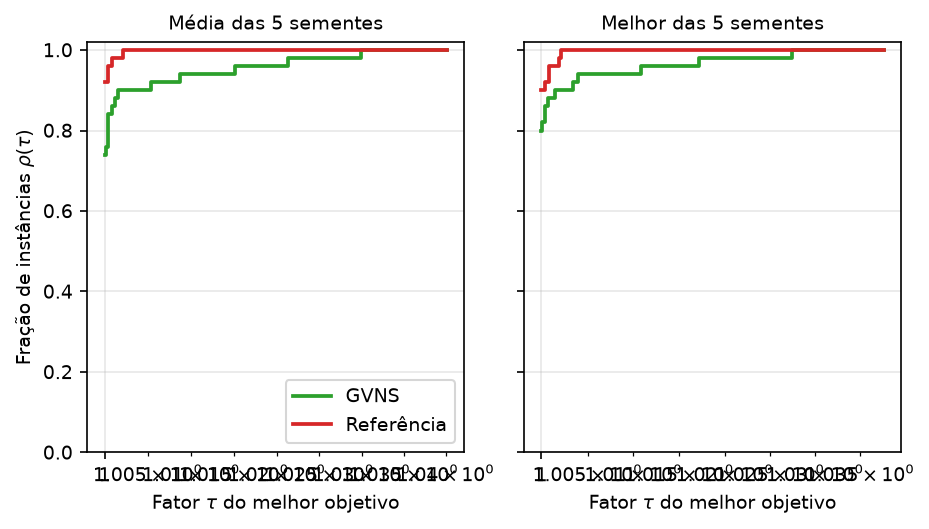

,visao,algo,rho(1),rho(1.01),rho(1.05),max_r
0,Média das 5 sementes,GVNS,0.74,0.94,1.0,1.029885
1,Média das 5 sementes,Referência,0.92,1.00,1.0,1.002139
2,Melhor das 5 sementes,GVNS,0.80,0.94,1.0,1.027449
3,Melhor das 5 sementes,Referência,0.90,1.00,1.0,1.002139


In [10]:
def perfil(r_g, r_r):
    best = np.maximum(r_g, r_r)
    return {"ils_vnd": best / r_g, "ref": best / r_r}

views = {"Média das 5 sementes": ("g_obj_med", "r_obj_med"), "Melhor das 5 sementes": ("g_obj_best", "r_obj_best")}
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H3), sharey=True)
rows_pp = []
for ax, (titulo, (cg, cr)) in zip(axes, views.items()):
    ratios = perfil(df_par[cg].values, df_par[cr].values)
    tmax = max(r.max() for r in ratios.values())
    taus = np.unique(np.concatenate([[1.0], np.concatenate(list(ratios.values())), [tmax * 1.01]]))
    for a in ALGOS:
        rho = [(ratios[a] <= t + 1e-12).mean() for t in taus]
        ax.step(taus, rho, where="post", color=COLORS[a], lw=1.8, label=ALGO_LABELS[a])
        rows_pp.append({"visao": titulo, "algo": ALGO_LABELS[a], "rho(1)": (ratios[a] <= 1 + 1e-12).mean(),
                        "rho(1.01)": (ratios[a] <= 1.01).mean(), "rho(1.05)": (ratios[a] <= 1.05).mean(), "max_r": ratios[a].max()})
    ax.set_xscale("log"); ax.set_title(titulo, fontsize=FONT_MIN)
    ax.set_xlabel(r"Fator $\tau$ do melhor objetivo"); ax.grid(alpha=0.3); ax.set_ylim(0, 1.02)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
axes[0].set_ylabel(r"Fração de instâncias $\rho(\tau)$")
axes[0].legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_3.pdf", bbox_inches="tight"); fig.savefig(OUTPUT_DIR / "fig_3_3.png", bbox_inches="tight")
df_pp = pd.DataFrame(rows_pp); df_pp.to_csv(OUTPUT_DIR / "fig_3_3_dados.csv", index=False)
plt.show(); display(df_pp)


## 10. Verificações Finais

In [11]:
_checks = []
def check(nome, cond, detalhe=""):
    _checks.append({"verificação": nome, "status": "ok" if cond else "FALHA", "detalhe": detalhe})
check("50 instâncias pareadas", len(df_par) == 50, str(len(df_par)))
check(f"{N_REPS} execuções por instância e método", set(df_inst.n_runs) == {N_REPS}, str(set(df_inst.n_runs)))
check("sementes idênticas", seeds_ok)
check("sem ausentes", not df_par.isna().any().any())
check("melhor <= média", bool(((df_par.g_best <= df_par.g_med + TOL) & (df_par.r_best <= df_par.r_med + TOL)).all()))
for ds in DATASETS + [None]:
    sub = df_par[df_par.dataset == ds] if ds else df_par
    for g, r in [("g_med", "r_med"), ("g_best", "r_best")]:
        w, t, l, _ = resumo_pareado(sub[g].values, sub[r].values)
        check(f"V+E+D=N — {DS_LABELS[ds] if ds else 'Geral'}/{g}", w + t + l == len(sub))
for f in sorted(OUTPUT_DIR.glob("tab_3_*.tex")):
    e = verificar_tex(f.read_text(encoding="utf-8").split("\n\n")[0], f.name)
    check(f"estrutura .tex — {f.name}", not e, "; ".join(e))
df_checks = pd.DataFrame(_checks); display(df_checks)
if (df_checks["status"] == "FALHA").any():
    raise AssertionError("Falha em verificações!")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:30s} {f.stat().st_size:8d} bytes")


,verificação,status,detalhe
0,50 instâncias pareadas,ok,50
1,5 execuções por instância e método,ok,{5}
2,sementes idênticas,ok,
3,sem ausentes,ok,
4,melhor <= média,ok,
5,V+E+D=N — A/g_med,ok,
6,V+E+D=N — A/g_best,ok,
7,V+E+D=N — B/g_med,ok,
8,V+E+D=N — B/g_best,ok,
9,V+E+D=N — X/g_med,ok,


  fig_3_1.pdf                       38852 bytes
  fig_3_1.png                       68002 bytes
  fig_3_2.pdf                       38362 bytes
  fig_3_2.png                       94352 bytes
  fig_3_2_dados.csv                  2023 bytes
  fig_3_3.pdf                       44174 bytes
  fig_3_3.png                      116731 bytes
  fig_3_3_dados.csv                   294 bytes
  tab_3_1.csv                         928 bytes
  tab_3_1.tex                        1132 bytes
  tab_3_2.csv                         609 bytes
  tab_3_2.tex                        1016 bytes
